# Table of Contents
- [4.0 Introduction](#intro)
- [4.1 Numerical differentiation: finite differences](#fd)
    - [Forward, backward and central differences](#fbc)
    - [Truncation error vs round-off error](#errors)
    - [Second derivatives](#second)
    - [Richardson extrapolation](#richardson)
- [4.2 Numerical integration (quadrature)](#quad)
    - [The rectangle (midpoint) rule](#midpoint)
    - [The trapezium rule](#trapezium)
    - [Simpson's rule](#simpson)
    - [Romberg integration](#romberg)
    - [Gaussian quadrature](#gauss)
    - [Improper integrals and singularities](#improper)
    - [Using `scipy.integrate`](#scipy)
- [Problems](#problems)

# 4.0 Introduction <a class="anchor" id="intro"></a>
Back in the introduction (notebook 00) we approximated $\int_0^\pi \sin x\,dx$ by adding up thin rectangles, and we saw the answer creep towards $2$ as $dx\to0$. In this chapter we'll do much better. The central question for every method is the same:

> **If I halve the step size $h$, how much smaller does the error get?**

If the error behaves like $h^p$ we say the method is **of order $p$**. Halving $h$ divides the error by $2^p$ - so a 4th order method gains a factor of 16 for twice the work, whereas a 1st order method only gains a factor of 2. Choosing a higher-order method is usually far cheaper than shrinking $h$.

In [1]:
# BLOCK 4.0.1
import numpy as np
import matplotlib.pyplot as plt

# 4.1 Numerical differentiation: finite differences <a class="anchor" id="fd"></a>
## Forward, backward and central differences <a class="anchor" id="fbc"></a>
Take the Taylor series of $f$ about $x$ with a small step $h$:

$$f(x+h) = f(x) + h f'(x) + \frac{h^2}{2}f''(x) + \frac{h^3}{6}f'''(x) + \dots \tag{1}$$
$$f(x-h) = f(x) - h f'(x) + \frac{h^2}{2}f''(x) - \frac{h^3}{6}f'''(x) + \dots \tag{2}$$

Rearranging (1) gives the **forward difference**, and (2) the **backward difference**:

$$f'(x) = \frac{f(x+h)-f(x)}{h} - \underbrace{\frac{h}{2}f''(x)}_{\text{error}\;\propto\;h} \qquad
  f'(x) = \frac{f(x)-f(x-h)}{h} + \frac{h}{2}f''(x)$$

Both are only first order. But subtract (2) from (1): the even terms cancel and we get the **central difference**

$$f'(x) = \frac{f(x+h)-f(x-h)}{2h} - \frac{h^2}{6}f'''(x) + \dots$$

which is **second order** for the same number of function evaluations. Symmetry is free accuracy!

In [2]:
# BLOCK 4.1.1
def forward(f, x, h):
    return (f(x + h) - f(x)) / h

def backward(f, x, h):
    return (f(x) - f(x - h)) / h

def central(f, x, h):
    return (f(x + h) - f(x - h)) / (2*h)

x0 = 1.0
exact = np.cos(x0)          # d/dx sin(x) = cos(x)
for h in [0.1, 0.01, 0.001]:
    print(f'h = {h:<6} forward error = {abs(forward(np.sin, x0, h) - exact):.2e}   '
          f'central error = {abs(central(np.sin, x0, h) - exact):.2e}')

h = 0.1    forward error = 4.29e-02   central error = 9.00e-04
h = 0.01   forward error = 4.22e-03   central error = 9.00e-06
h = 0.001  forward error = 4.21e-04   central error = 9.01e-08


Each time $h$ shrinks by 10, the forward error shrinks by 10 (first order) but the central error shrinks by 100 (second order).

## Truncation error vs round-off error <a class="anchor" id="errors"></a>
So why not just take $h=10^{-15}$? Because computers store numbers with about 16 significant figures (double precision, machine epsilon $\varepsilon\approx2.2\times10^{-16}$). When $h$ is tiny, $f(x+h)$ and $f(x)$ agree in almost every digit and subtracting them destroys the precision - this is called **catastrophic cancellation**. The round-off error behaves like $\varepsilon/h$, which *grows* as $h$ shrinks.

The total error is therefore roughly

$$E(h) \approx \underbrace{C h^p}_{\text{truncation}} + \underbrace{\frac{\varepsilon}{h}}_{\text{round-off}},$$

which has a minimum at an optimal $h$. Let's find it experimentally.

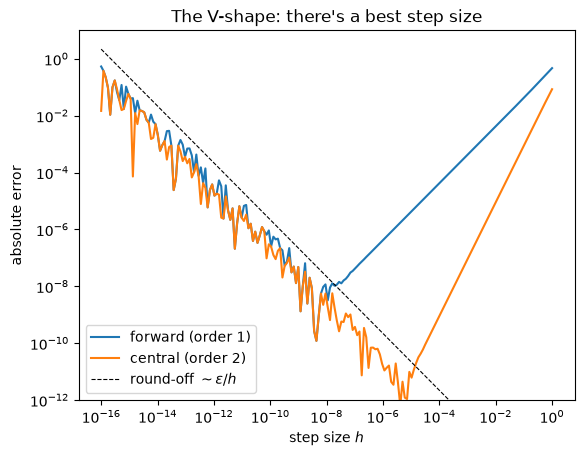

best h (forward) ~ 4.3e-09,  best h (central) ~ 4.1e-06


In [3]:
# BLOCK 4.1.2
hs = np.logspace(-16, 0, 200)
err_f = np.abs(forward(np.sin, x0, hs) - exact)
err_c = np.abs(central(np.sin, x0, hs) - exact)

plt.loglog(hs, err_f, label='forward (order 1)')
plt.loglog(hs, err_c, label='central (order 2)')
plt.loglog(hs, 2.2e-16/hs, 'k--', lw=0.8, label=r'round-off $\sim\varepsilon/h$')
plt.xlabel('step size $h$'); plt.ylabel('absolute error')
plt.title("The V-shape: there's a best step size")
plt.legend(); plt.ylim(1e-12, 1e1); plt.show()
print(f'best h (forward) ~ {hs[np.argmin(err_f)]:.1e},  best h (central) ~ {hs[np.argmin(err_c)]:.1e}')

The rule of thumb: $h_{\text{opt}}\sim\sqrt{\varepsilon}\approx10^{-8}$ for forward differences and $h_{\text{opt}}\sim\varepsilon^{1/3}\approx10^{-5}$ for central differences.

## Second derivatives <a class="anchor" id="second"></a>
Adding (1) and (2) instead cancels the odd terms:

$$f''(x) = \frac{f(x+h) - 2f(x) + f(x-h)}{h^2} + \mathcal{O}(h^2).$$

This "1, -2, 1" stencil is *everywhere* in physics: it's how we will discretise the kinetic energy operator $-\frac{\hbar^2}{2m}\frac{d^2}{dx^2}$ in quantum mechanics, and the Laplacian $\nabla^2$ in the heat, wave and Poisson equations (Chapters 6 and 7).

In [4]:
# BLOCK 4.1.3
def second_derivative(f, x, h):
    return (f(x + h) - 2*f(x) + f(x - h)) / h**2

for h in [0.1, 0.01, 0.001]:
    print(f'h = {h:<6} f\'\'(1) ~ {second_derivative(np.sin, 1.0, h):.10f}   (exact {-np.sin(1.0):.10f})')

h = 0.1    f''(1) ~ -0.8407699927   (exact -0.8414709848)
h = 0.01   f''(1) ~ -0.8414639726   (exact -0.8414709848)
h = 0.001  f''(1) ~ -0.8414709147   (exact -0.8414709848)


Often we don't have a function at all, but an **array of data** (e.g. positions from an experiment). `np.gradient` applies central differences in the interior and one-sided differences at the edges:

In [5]:
# BLOCK 4.1.4
t = np.linspace(0, 2, 41)                  # time (s)
y = 20*t - 0.5*9.81*t**2                   # height of a ball thrown upwards (m)
v = np.gradient(y, t)                      # velocity
a = np.gradient(v, t)                      # acceleration
print('velocity at t=0, 1, 2 s:', np.round(v[[0, 20, 40]], 4))
print('acceleration (should be -9.81):', np.round(a[18:23], 4))

velocity at t=0, 1, 2 s: [19.7548 10.19    0.6253]
acceleration (should be -9.81): [-9.81 -9.81 -9.81 -9.81 -9.81]


## Richardson extrapolation <a class="anchor" id="richardson"></a>
Here is one of the most beautiful ideas in numerical analysis. Suppose an approximation $D(h)$ has error expansion $D(h) = D + c h^2 + \mathcal{O}(h^4)$. Then

$$D(h/2) = D + c\frac{h^2}{4} + \mathcal{O}(h^4).$$

Two equations, and we can eliminate the unknown $c$:

$$D = \frac{4D(h/2) - D(h)}{3} + \mathcal{O}(h^4).$$

We combined two *second*-order answers into a *fourth*-order one, without knowing $c$! In general, for an error $\propto h^p$, the improved estimate is $\dfrac{2^pD(h/2)-D(h)}{2^p-1}$.

In [6]:
# BLOCK 4.1.5
def richardson_central(f, x, h):
    return (4*central(f, x, h/2) - central(f, x, h)) / 3

for h in [0.4, 0.2, 0.1, 0.05]:
    print(f'h = {h:<5} central error = {abs(central(np.sin, x0, h) - exact):.2e}   '
          f'Richardson error = {abs(richardson_central(np.sin, x0, h) - exact):.2e}')

h = 0.4   central error = 1.43e-02   Richardson error = 2.87e-05
h = 0.2   central error = 3.59e-03   Richardson error = 1.80e-06
h = 0.1   central error = 9.00e-04   Richardson error = 1.13e-07
h = 0.05  central error = 2.25e-04   Richardson error = 7.03e-09


Halving $h$ now divides the error by $\approx16$. Keep this trick in mind - it's the engine behind Romberg integration below.

# 4.2 Numerical integration (quadrature) <a class="anchor" id="quad"></a>
We want $I = \int_a^b f(x)\,dx$. Split $[a,b]$ into $N$ strips of width $h=(b-a)/N$ with nodes $x_i = a + ih$. All the methods below approximate $f$ on each strip by a simple polynomial that we *can* integrate exactly.

Our running test case will be $\int_0^\pi \sin x\,dx = 2$ (an old friend from notebook 00).

## The rectangle (midpoint) rule <a class="anchor" id="midpoint"></a>
Approximate $f$ on each strip by a constant equal to its value at the **middle** of the strip:

$$I \approx h\sum_{i=0}^{N-1} f\!\left(a + (i+\tfrac12)h\right).$$

The notebook 00 integrator used the *left* edge of each strip, which is only first order. Using the midpoint is a free upgrade to second order (by the same symmetry argument as central differences).

In [7]:
# BLOCK 4.2.1
def midpoint(f, a, b, N):
    h = (b - a) / N
    x = a + (np.arange(N) + 0.5)*h
    return h*np.sum(f(x))

def left_rectangle(f, a, b, N):
    h = (b - a) / N
    x = a + np.arange(N)*h
    return h*np.sum(f(x))

for N in [10, 100, 1000]:
    print(f'N = {N:<5} left-rectangle error = {abs(left_rectangle(np.sin, 0, np.pi, N) - 2):.2e}   '
          f'midpoint error = {abs(midpoint(np.sin, 0, np.pi, N) - 2):.2e}')

N = 10    left-rectangle error = 1.65e-02   midpoint error = 8.25e-03
N = 100   left-rectangle error = 1.64e-04   midpoint error = 8.22e-05
N = 1000  left-rectangle error = 1.64e-06   midpoint error = 8.22e-07


Notice we did not need a `for` loop: `np.sum(f(x))` evaluates $f$ on the whole array at once. This *vectorisation* is typically 10-100$\times$ faster than looping in Python.

## The trapezium rule <a class="anchor" id="trapezium"></a>
Join neighbouring points with straight lines and add up the areas of the trapezia:

$$I \approx \frac{h}{2}\left[f_0 + 2f_1 + 2f_2 + \dots + 2f_{N-1} + f_N\right], \qquad \text{error} = -\frac{(b-a)h^2}{12}f''(\eta).$$

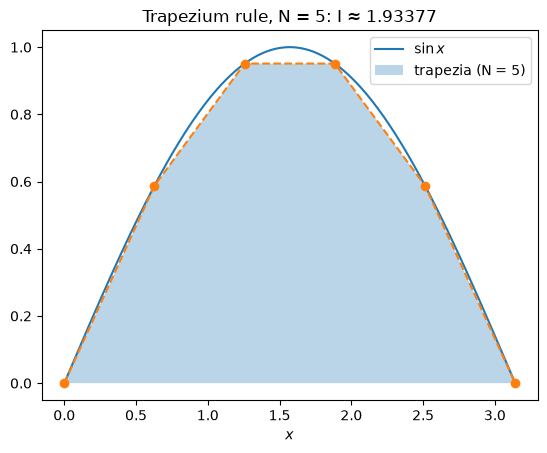

In [8]:
# BLOCK 4.2.2
def trapezium(f, a, b, N):
    x = np.linspace(a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    return h*(0.5*y[0] + np.sum(y[1:-1]) + 0.5*y[-1])

# A picture is worth 1000 words
x = np.linspace(0, np.pi, 300)
xn = np.linspace(0, np.pi, 6)
plt.plot(x, np.sin(x), label=r'$\sin x$')
plt.fill_between(xn, np.sin(xn), alpha=0.3, label='trapezia (N = 5)')
plt.plot(xn, np.sin(xn), 'o--')
plt.legend(); plt.xlabel('$x$')
plt.title(f'Trapezium rule, N = 5: I ≈ {trapezium(np.sin, 0, np.pi, 5):.5f}')
plt.show()

## Simpson's rule <a class="anchor" id="simpson"></a>
Instead of straight lines, fit a **parabola** through each *pair* of strips (three points). Integrating the parabola gives Simpson's famous $1, 4, 2, 4, \dots, 2, 4, 1$ weights ($N$ must be even):

$$I \approx \frac{h}{3}\left[f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 4f_{N-1} + f_N\right], \qquad \text{error} = -\frac{(b-a)h^4}{180}f^{(4)}(\eta).$$

Simpson's rule is fourth order. Surprisingly, it is *exact* for cubics, not just quadratics - another gift from symmetry.

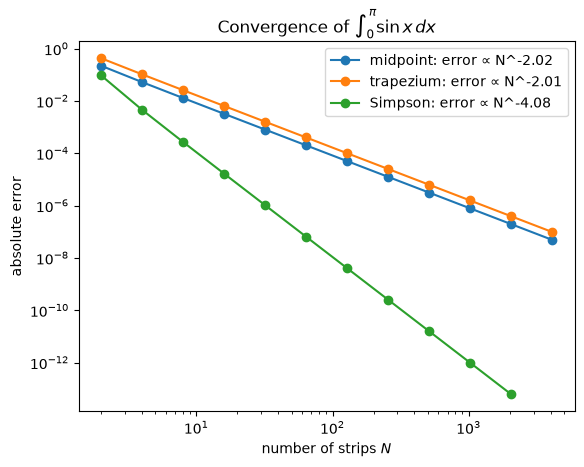

In [9]:
# BLOCK 4.2.3
def simpson(f, a, b, N):
    if N % 2:
        raise ValueError('Simpson\'s rule needs an even number of strips')
    x = np.linspace(a, b, N + 1)
    y = f(x)
    h = (b - a) / N
    return h/3*(y[0] + 4*np.sum(y[1:-1:2]) + 2*np.sum(y[2:-1:2]) + y[-1])

# Convergence study - the most important plot in this chapter
Ns = 2**np.arange(1, 13)
rules = {'midpoint': midpoint, 'trapezium': trapezium, 'Simpson': simpson}
for name, rule in rules.items():
    errs = np.array([abs(rule(np.sin, 0, np.pi, N) - 2) for N in Ns])
    mask = errs > 1e-14
    p = -np.polyfit(np.log(Ns[mask][:6]), np.log(errs[mask][:6]), 1)[0]
    plt.loglog(Ns[mask], errs[mask], 'o-', label=f'{name}: error ∝ N^-{p:.2f}')
plt.xlabel('number of strips $N$'); plt.ylabel('absolute error')
plt.title(r'Convergence of $\int_0^\pi \sin x\,dx$')
plt.legend(); plt.show()

On a log-log plot a power law is a straight line whose gradient is the order. Simpson hits machine precision with ~1000 strips, long before the others.

## Romberg integration <a class="anchor" id="romberg"></a>
The trapezium rule error has an expansion in **even** powers of $h$ only (this is the Euler-Maclaurin formula):

$$T(h) = I + c_2h^2 + c_4h^4 + c_6h^6 + \dots$$

That is precisely the situation for repeated Richardson extrapolation. Build a triangular table: the first column is the trapezium rule with $h, h/2, h/4,\dots$, and each subsequent column removes the next power of $h$:

$$R_{k,j} = \frac{4^j R_{k,j-1} - R_{k-1,j-1}}{4^j - 1}.$$

(Fun fact: column $j=1$ is exactly Simpson's rule.)

In [10]:
# BLOCK 4.2.4
def romberg(f, a, b, levels=6):
    R = np.zeros((levels, levels))
    for k in range(levels):
        R[k, 0] = trapezium(f, a, b, 2**k)
        for j in range(1, k + 1):
            R[k, j] = (4**j*R[k, j-1] - R[k-1, j-1]) / (4**j - 1)
    return R

R = romberg(np.sin, 0, np.pi)
np.set_printoptions(precision=12, suppress=True, linewidth=120)
print(R)
print(f'\nbest estimate {R[-1, -1]:.15f}, error {abs(R[-1, -1] - 2):.1e}  using only {2**5 + 1} function values')

[[0.             0.             0.             0.             0.             0.            ]
 [1.570796326795 2.094395102393 0.             0.             0.             0.            ]
 [1.896118897937 2.004559754984 1.998570731824 0.             0.             0.            ]
 [1.974231601946 2.000269169948 1.999983130946 2.00000554998  0.             0.            ]
 [1.993570343772 2.000016591048 1.999999752455 2.000000016288 1.999999994587 0.            ]
 [1.99839336097  2.000001033369 1.999999996191 2.00000000006  1.999999999996 2.000000000001]]

best estimate 2.000000000001321, error 1.3e-12  using only 33 function values


## Gaussian quadrature <a class="anchor" id="gauss"></a>
All the previous rules used *equally spaced* points. What if we are free to choose both the positions $x_i$ **and** the weights $w_i$ in

$$\int_{-1}^{1} f(x)\,dx \approx \sum_{i=1}^{n} w_i f(x_i)?$$

That's $2n$ free parameters, so we can make the rule exact for every polynomial up to degree $2n-1$. Gauss showed that the optimal nodes are the roots of the **Legendre polynomial** $P_n(x)$ (yes, the same Legendre polynomials from the hydrogen atom and multipole expansions!).

For a general interval $[a,b]$, substitute $x = \tfrac{b-a}{2}t + \tfrac{a+b}{2}$.

In [11]:
# BLOCK 4.2.5
def gauss_legendre(f, a, b, n):
    t, w = np.polynomial.legendre.leggauss(n)    # nodes and weights on [-1, 1]
    x = 0.5*(b - a)*t + 0.5*(a + b)
    return 0.5*(b - a)*np.sum(w*f(x))

print(' n   Gauss-Legendre error   Simpson error (same number of points)')
for n in [3, 5, 7, 9, 11]:
    print(f'{n:>2}   {abs(gauss_legendre(np.sin, 0, np.pi, n) - 2):.2e}               '
          f'{abs(simpson(np.sin, 0, np.pi, n - 1) - 2):.2e}')

 n   Gauss-Legendre error   Simpson error (same number of points)
 3   1.39e-03               9.44e-02
 5   1.10e-07               4.56e-03
 7   1.79e-12               8.63e-04
 9   4.44e-16               2.69e-04
11   0.00e+00               1.10e-04


With 11 function evaluations Gauss-Legendre is at machine precision. For smooth integrands it is spectacularly efficient - this is why it's used inside finite-element codes and many physics simulations.

## Improper integrals and singularities <a class="anchor" id="improper"></a>
Physics loves infinite ranges: $\int_0^\infty$ appears in blackbody radiation, partition functions and Fourier transforms. Two standard tricks:

1. **Change of variables** to map $[0,\infty)$ onto a finite interval, e.g. $x = t/(1-t)$, $dx = dt/(1-t)^2$, so $t\in[0,1)$.
2. **Use a rule that never evaluates the endpoint**, such as the midpoint rule or Gauss-Legendre, so an integrable singularity at the end (e.g. $1/\sqrt{x}$) never causes a division by zero.

Let's compute the famous blackbody integral $\displaystyle\int_0^\infty \frac{x^3}{e^x-1}dx = \frac{\pi^4}{15}$.

In [12]:
# BLOCK 4.2.6
def planck(x):
    # expm1(x) = e^x - 1, accurate for small x. For huge x it overflows to inf,
    # giving x^3/inf = 0, which is the correct limit - so we silence the warning.
    with np.errstate(over='ignore'):
        return x**3 / np.expm1(x)

def mapped(t):
    x = t / (1 - t)
    return planck(x) / (1 - t)**2

for n in [10, 20, 40, 80]:
    print(f'n = {n:<3}  I ≈ {gauss_legendre(mapped, 0, 1, n):.12f}')
print(f'exact    {np.pi**4/15:.12f}')

n = 10   I ≈ 6.572142992176
n = 20   I ≈ 6.493242550962
n = 40   I ≈ 6.493939265516
n = 80   I ≈ 6.493939402267
exact    6.493939402267


## Using `scipy.integrate` <a class="anchor" id="scipy"></a>
In real life you'll mostly use:
- `scipy.integrate.quad(f, a, b)` - adaptive Gauss-Kronrod quadrature from the QUADPACK Fortran library. Handles `np.inf` limits and returns an error estimate.
- `scipy.integrate.simpson(y, x=x)` and `np.trapezoid(y, x)` - for **sampled data** you can't re-evaluate.
- `scipy.integrate.dblquad`, `tplquad`, `nquad` - multi-dimensional integrals.

"Adaptive" means the routine estimates the error on each sub-interval and only refines where it needs to - putting points where the function is difficult.

In [13]:
# BLOCK 4.2.7
from scipy import integrate

I, err = integrate.quad(planck, 0, np.inf)
print(f'quad  : {I:.15f} ± {err:.1e}   (exact {np.pi**4/15:.15f})')

x = np.linspace(0, np.pi, 101)
print(f'simpson on data   : {integrate.simpson(np.sin(x), x=x):.12f}')
print(f'trapezoid on data : {np.trapezoid(np.sin(x), x):.12f}')

# A 2D example: the area of a unit circle as a double integral (should be pi)
area, _ = integrate.dblquad(lambda y, x: 1.0, -1, 1, lambda x: -np.sqrt(1 - x**2), lambda x: np.sqrt(1 - x**2))
print(f'area of unit circle: {area:.12f}')

quad  : 6.493939402266830 ± 2.6e-09   (exact 6.493939402266828)
simpson on data   : 2.000000010825
trapezoid on data : 1.999835503887
area of unit circle: 3.141592653590


# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - Higher-order stencils
By combining Taylor series for $f(x\pm h)$ and $f(x\pm 2h)$, derive the fourth-order central difference
$f'(x)\approx\dfrac{-f(x+2h)+8f(x+h)-8f(x-h)+f(x-2h)}{12h}$. Plot its error against $h$ alongside the second-order formula and find its optimal $h$.

### Exercise 2 - The period of a pendulum
The period of a pendulum of length $L$ released from angle $\theta_0$ is
$$T = 4\sqrt{\frac{L}{g}}\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-k^2\sin^2\phi}},\qquad k=\sin(\theta_0/2).$$
Evaluate it with Simpson's rule for $\theta_0$ from $1^\circ$ to $179^\circ$ and plot $T/T_0$ where $T_0=2\pi\sqrt{L/g}$. When does the small-angle approximation fail by more than 1%? Check against `scipy.special.ellipk(k**2)`.

### Exercise 3 - A singular integrand
Compute $\int_0^1 \frac{\cos x}{\sqrt{x}}\,dx$ with the midpoint rule. What order of convergence do you observe? Now substitute $x=u^2$ and repeat. Explain the difference.

### Exercise 4 - Adaptive Simpson
Write a *recursive* function `adaptive_simpson(f, a, b, tol)` which compares Simpson on $[a,b]$ with Simpson on the two halves, and only recurses into a half if the difference is larger than `tol`. Count how many function evaluations it needs for $\int_0^1\sqrt{x}\,dx$.

In [14]:
# Start working here